# IGC flight log → DataFrame / CSV

## この Notebook で扱うもの

この Notebook は、IGC flight log の有効な B-record を読み取り、離陸滑走開始を基準とした解析用の時系列 DataFrame に変換する。

主な出力は次のとおりである。

- UTC 時刻と離陸滑走開始からの経過時間
- WGS84 緯度・経度
- 離陸滑走開始点を原点とする NED 座標 $(x,y,z)$
- IGC に記録された pressure altitude / GNSS altitude
- 離陸滑走開始点からの相対 GNSS 高度
- 地上投影した飛行軌跡に沿う累積水平距離
- 各 IGC と同名の CSV

処理の流れは次のとおりである。

```text
IGC file
    ↓
HFDTEDATE と有効 B-record を読む
    ↓
LXNA::PHASE:takingOff を探索アンカーとして取得
    ↓
takingOff 前 15 s の水平移動を調べる
    ↓
最後の静止サンプルを離陸滑走開始点とする
    ↓
WGS84 geodetic → ECEF → local NED
    ↓
離陸滑走開始を共通原点にする
    ↓
time_s / relative_altitude_m /
ground_track_distance_m を計算
    ↓
DataFrame / CSV
```

> **重要**  
> `LXNA::PHASE:takingOff` 自体を離陸滑走開始とはみなさない。この記録は、離陸滑走開始を探索する位置を限定するためのアンカーとしてのみ用いる。

---

## 1. IGC B-record から読み取る値

この Notebook では、fix validity が `A` の B-record のみを使用する。

B-record から読み取る主な値は、

- UTC (`HHMMSS`)
- 緯度 (`DDMMmmm`)
- 経度 (`DDDMMmmm`)
- pressure altitude
- GNSS altitude

である。

緯度は

$$
\phi_{\mathrm{deg}}
=DD+\frac{MMmmm}{1000\times60},
$$

経度は

$$
\lambda_{\mathrm{deg}}
=DDD+\frac{MMmmm}{1000\times60}
$$

として decimal degree へ変換する。南緯と西経は負値とする。

飛行日はファイル名ではなく IGC header の `HFDTEDATE:` から取得する。

---

## 2. WGS84 geodetic → ECEF → NED

緯度 $\phi$、経度 $\lambda$、高度 $h$ を WGS84 geodetic coordinates とし、まず ECEF (Earth-Centered, Earth-Fixed) 座標へ変換する。

WGS84 の長半径を $a$、扁平率を $f$ とすると、第一離心率の二乗は

$$
e^2=f(2-f)
$$

であり、卯酉線曲率半径は

$$
N(\phi)=\frac{a}{\sqrt{1-e^2\sin^2\phi}}
$$

である。

ECEF 座標は

$$
\begin{aligned}
X&=(N+h)\cos\phi\cos\lambda,\\
Y&=(N+h)\cos\phi\sin\lambda,\\
Z&=\left[N(1-e^2)+h\right]\sin\phi
\end{aligned}
$$

とする。

基準点の ECEF 座標との差

$$
\Delta\mathbf r=
\begin{bmatrix}
\Delta X & \Delta Y & \Delta Z
\end{bmatrix}^{T}
$$

を、基準点の緯度・経度を用いて local NED (North-East-Down) へ回転する。

この Notebook の列名との対応は、

```text
x_m = North

y_m = East

z_m = Down
```

である。したがって **上昇すると `z_m` は負になる**。

`_geodetic_to_ned()` は「入力された最初のサンプル」を NED 原点とする。離陸滑走開始点の決定はこの関数ではなく `igc_to_df()` 側で行う。

高度 $h$ には `GNSS_alt` を用いる。使用する IGC の GNSS altitude の基準が、この座標変換に適したものかは logger の header / 仕様を確認すること。本 Notebook の作成時に用いた SeeYou Navigator の IGC では `HFALGALTGPS:ELL` が記録されている。

---

## 3. 離陸滑走開始の検出

`LXNA::PHASE:takingOff` は離陸滑走開始そのものではないため、次の手順で開始点を推定する。

1. 全有効 B-record を読み取る。
2. 一時的に NED 座標へ変換する。
3. 隣接サンプル間の水平対地速度を求める。
4. `takingOff` の前 15 s だけを探索する。
5. その区間で水平対地速度が 4 km/h 以下となる **最後のサンプル**を、継続的な前進開始直前の静止サンプルとして採用する。

隣接サンプル $i-1$ と $i$ の水平対地速度は、

$$
V_{g,i}
=
\frac{
\sqrt{
(N_i-N_{i-1})^2+(E_i-E_{i-1})^2
}
}{t_i-t_{i-1}}
$$

で求める。コードでは m/s から km/h へ変換するため $3.6$ を掛ける。

判定値はコード中の

```python
takeoff_search_window_s = 15
stationary_ground_speed_kmh = 4.0
```

である。

> **重要**  
> `15 s` と `4.0 km/h` は IGC 規格や Naviter の公式定数ではない。本 Notebook の 1 Hz IGC データで、停止中の GPS / 座標量子化による見かけの移動を避けながら離陸滑走開始を安定して検出するために採用した判定値である。別の logger、サンプルレート、機体、運用条件では見直す余地がある。

検出した開始サンプルを、時間・位置・高度・累積距離の共通原点とする。

---

## 4. 出力 DataFrame

`igc_to_df(path)` は次の列を返す。

| 列 | 単位 | 内容 |
|---|---:|---|
| `igc_index` | - | 元 IGC 内の行 index |
| `UTC_time` | - | B-record の UTC datetime |
| `time_s` | s | 離陸滑走開始からの経過時間 |
| `latitude` | deg | WGS84 緯度 |
| `longitude` | deg | WGS84 経度 |
| `x_m` | m | NED North |
| `y_m` | m | NED East |
| `z_m` | m | NED Down |
| `press_alt` | m | IGC B-record の pressure altitude field |
| `GNSS_alt` | m | IGC B-record の GNSS altitude field |
| `relative_altitude_m` | m | 離陸滑走開始点からの GNSS 高度差 |
| `ground_track_distance_m` | m | 水平面に投影した飛行軌跡に沿う累積距離 |

相対高度は

$$
h_{\mathrm{rel},i}=h_{\mathrm{GNSS},i}-h_{\mathrm{GNSS},0}
$$

である。

累積水平距離は

$$
s_i
=
\sum_{k=1}^{i}
\sqrt{
(x_k-x_{k-1})^2+(y_k-y_{k-1})^2
}
$$

である。

したがって `ground_track_distance_m` は原点から現在位置までの直線距離

$$
\sqrt{x_i^2+y_i^2}
$$

とは異なる。旋回して原点付近へ戻っても、`ground_track_distance_m` はそれまでに進んだ水平距離を保持して単調非減少となる。


In [18]:
import datetime
import glob
from pathlib import Path
import numpy as np
import pandas as pd


def _geodetic_to_ned(latitude_deg, longitude_deg, altitude_m):
  # WGS84 geodetic coordinates -> ECEF
  latitude_rad = np.radians(np.asarray(latitude_deg, dtype=float))
  longitude_rad = np.radians(np.asarray(longitude_deg, dtype=float))
  altitude_m = np.asarray(altitude_m, dtype=float)

  semi_major_axis_m = 6378137.0
  flattening = 1.0 / 298.257223563
  eccentricity_squared = flattening * (2.0 - flattening)

  sin_latitude = np.sin(latitude_rad)
  cos_latitude = np.cos(latitude_rad)
  sin_longitude = np.sin(longitude_rad)
  cos_longitude = np.cos(longitude_rad)

  prime_vertical_radius_m = semi_major_axis_m / np.sqrt(
    1.0 - eccentricity_squared * sin_latitude**2
  )

  ecef_x_m = (prime_vertical_radius_m + altitude_m) * cos_latitude * cos_longitude
  ecef_y_m = (prime_vertical_radius_m + altitude_m) * cos_latitude * sin_longitude
  ecef_z_m = (
    prime_vertical_radius_m * (1.0 - eccentricity_squared) + altitude_m
  ) * sin_latitude

  # Use the first input sample as the local NED origin.
  latitude_0 = latitude_rad[0]
  longitude_0 = longitude_rad[0]
  dx_m = ecef_x_m - ecef_x_m[0]
  dy_m = ecef_y_m - ecef_y_m[0]
  dz_m = ecef_z_m - ecef_z_m[0]

  north_m = (
    -np.sin(latitude_0) * np.cos(longitude_0) * dx_m
    -np.sin(latitude_0) * np.sin(longitude_0) * dy_m
    +np.cos(latitude_0) * dz_m
  )
  east_m = -np.sin(longitude_0) * dx_m + np.cos(longitude_0) * dy_m
  down_m = (
    -np.cos(latitude_0) * np.cos(longitude_0) * dx_m
    -np.cos(latitude_0) * np.sin(longitude_0) * dy_m
    -np.sin(latitude_0) * dz_m
  )

  return north_m, east_m, down_m


def igc_to_df(path):
  with open(path) as f:
    igcfile = [line.rstrip("\n") for line in f]

  # Read the flight date from the IGC header rather than from the filename.
  date_line = next((line for line in igcfile if line.startswith("HFDTEDATE:")), None)
  if date_line is None:
    raise ValueError("HFDTEDATE header was not found in the IGC file.")
  date = datetime.datetime.strptime(date_line.split(":", 1)[1][:6], "%d%m%y").date()

  # LXNA::PHASE:takingOff is not the start of the takeoff roll.  Use it only
  # as an anchor for finding the last stationary sample before sustained motion.
  taking_off_marker_index = next(
    (idx for idx, line in enumerate(igcfile) if line == "LXNA::PHASE:takingOff"),
    None,
  )
  if taking_off_marker_index is None:
    raise ValueError("LXNA::PHASE:takingOff was not found in the IGC file.")

  # Parse every valid B-record first so the ground run before takingOff remains
  # available for takeoff-roll start detection.
  records = []
  for igc_index, line in enumerate(igcfile):
    if not line.startswith("B") or len(line) < 35 or line[24] != "A":
      continue

    time_text = line[1:7]
    utc_time = datetime.datetime(
      date.year,
      date.month,
      date.day,
      int(time_text[0:2]),
      int(time_text[2:4]),
      int(time_text[4:6]),
    )

    latitude_text = line[7:14]
    latitude = int(latitude_text[0:2]) + int(latitude_text[2:7]) / 1000.0 / 60.0
    if line[14] == "S":
      latitude = -latitude

    longitude_text = line[15:23]
    longitude = int(longitude_text[0:3]) + int(longitude_text[3:8]) / 1000.0 / 60.0
    if line[23] == "W":
      longitude = -longitude

    records.append([
      igc_index,
      utc_time,
      latitude,
      longitude,
      float(line[25:30]),
      float(line[30:35]),
    ])

  if not records:
    raise ValueError("No valid B-record was found in the IGC file.")

  df_B = pd.DataFrame(
    records,
    columns=["igc_index", "UTC_time", "latitude", "longitude", "press_alt", "GNSS_alt"],
  )

  first_after_taking_off = df_B.index[df_B["igc_index"] > taking_off_marker_index]
  if len(first_after_taking_off) == 0:
    raise ValueError("No valid B-record was found after LXNA::PHASE:takingOff.")
  taking_off_time = df_B.loc[first_after_taking_off[0], "UTC_time"]

  # IGC coordinates are quantized finely enough that a one-sample GPS jump can
  # look like about 5 km/h while stationary.  Search only the 15 s before the
  # takingOff phase, and choose the last sample at <= 4 km/h.  By definition,
  # the samples after it remain in sustained motion up to takingOff.
  detection_north_m, detection_east_m, _ = _geodetic_to_ned(
    df_B["latitude"],
    df_B["longitude"],
    df_B["GNSS_alt"],
  )
  detection_dt_s = df_B["UTC_time"].diff().dt.total_seconds()
  detection_ground_speed_kmh = (
    np.hypot(pd.Series(detection_north_m).diff(), pd.Series(detection_east_m).diff())
    / detection_dt_s
    * 3.6
  )

  takeoff_search_window_s = 15
  stationary_ground_speed_kmh = 4.0
  search_start_time = taking_off_time - datetime.timedelta(seconds=takeoff_search_window_s)
  stationary_before_taking_off = df_B.index[
    (df_B["UTC_time"] >= search_start_time)
    & (df_B["igc_index"] < taking_off_marker_index)
    & (detection_ground_speed_kmh <= stationary_ground_speed_kmh)
  ]
  if len(stationary_before_taking_off) == 0:
    raise ValueError("Takeoff-roll start could not be detected before LXNA::PHASE:takingOff.")

  takeoff_roll_start_index = stationary_before_taking_off[-1]
  df_B = df_B.loc[takeoff_roll_start_index:].copy().reset_index(drop=True)

  # Time, position, altitude, and traveled distance share the detected
  # takeoff-roll start sample as their common origin.
  df_B["time_s"] = (df_B["UTC_time"] - df_B["UTC_time"].iloc[0]).dt.total_seconds()

  df_B["x_m"], df_B["y_m"], df_B["z_m"] = _geodetic_to_ned(
    df_B["latitude"],
    df_B["longitude"],
    df_B["GNSS_alt"],
  )

  df_B["relative_altitude_m"] = df_B["GNSS_alt"] - df_B["GNSS_alt"].iloc[0]
  df_B["ground_track_distance_m"] = (
    np.hypot(df_B["x_m"].diff(), df_B["y_m"].diff())
    .fillna(0.0)
    .cumsum()
  )

  return df_B[[
    "igc_index",
    "UTC_time",
    "time_s",
    "latitude",
    "longitude",
    "x_m",
    "y_m",
    "z_m",
    "press_alt",
    "GNSS_alt",
    "relative_altitude_m",
    "ground_track_distance_m",
  ]]


ROOT = Path.cwd()
if ROOT.name == "notebooks":
  ROOT = ROOT.parent


## 5. IGC を読み込んで CSV に変換する

### 最も簡単な使い方

1. `data/flight_validation/raw/` に解析したい `.igc` ファイルを置く。
2. Notebook を上から実行する。
3. `data/flight_validation/raw/` の IGC を取得する。
4. 各 IGC に対して `igc_to_df()` を実行する。
5. `data/flight_validation/processed/` に同じ basename の `.csv` を保存する。
6. 変換後 DataFrame は `df_dict[file]` から参照できる。

たとえば `flight01.igc` があれば、

```text
flight01.igc
    ↓
igc_to_df("flight01.igc")
    ↓
flight01.csv
```

となる。

### 1ファイルだけ直接変換する場合

一括処理を使わず、次のように呼び出してもよい。

```python
df = igc_to_df("flight01.igc")
df.to_csv("flight01.csv", index=False)
```

現在の一括保存コードは pandas の既定動作により DataFrame index も CSV に保存する。不要なら、下の `to_csv(...)` を

```python
df_dict[file].to_csv(file.replace(".igc", ".csv"), index=False)
```

へ変更する。

### シミュレータ CSV との比較

下のセルでは、IGC から作成した DataFrame に加えて、別途生成したシミュレータ履歴 CSV を `df_dict` に追加して比較できる。

```python
simulator_file = r"...history.csv"
```

は **repository内の `outputs/` パス**なので、別の環境で使用するときは自分のファイルパスへ書き換える。シミュレータとの比較が不要なら、この2行をコメントアウトまたは削除してよい。


In [19]:
raw_directory = ROOT / "data" / "flight_validation" / "raw"
processed_directory = ROOT / "data" / "flight_validation" / "processed"
processed_directory.mkdir(parents=True, exist_ok=True)

files = sorted(raw_directory.glob("*.igc"))
print(files)

df_dict = {}
for file in files:
  df_dict[str(file)] = igc_to_df(path=file)
  df_dict[str(file)].to_csv(processed_directory / f"{file.stem}.csv", index=False)

simulator_file = (
  ROOT
  / "outputs"
  / "g103a_club_sop_dynamic_winch_fem"
  / "g103a_club_sop_dynamic_winch_fem_history.csv"
)
if simulator_file.exists():
  df_dict[str(simulator_file)] = pd.read_csv(simulator_file)


['./igc\\2026-04-05-XNA-B266DCFEBE4B7119D2D6AB42C3F0BC2B-01.igc', './igc\\2026-04-05-XNA-B266DCFEBE4B7119D2D6AB42C3F0BC2B-02.igc', './igc\\2026-04-05-XNA-B266DCFEBE4B7119D2D6AB42C3F0BC2B-03.igc', './igc\\2026-04-05-XNA-B266DCFEBE4B7119D2D6AB42C3F0BC2B-04.igc', './igc\\2026-04-11-XNA-B266DCFEBE4B7119D2D6AB42C3F0BC2B-01.igc', './igc\\2026-04-11-XNA-B266DCFEBE4B7119D2D6AB42C3F0BC2B-02.igc', './igc\\2026-04-12-XNA-B266DCFEBE4B7119D2D6AB42C3F0BC2B-01.igc', './igc\\2026-04-12-XNA-B266DCFEBE4B7119D2D6AB42C3F0BC2B-02.igc', './igc\\2026-04-19-XNA-B266DCFEBE4B7119D2D6AB42C3F0BC2B-01.igc', './igc\\2026-04-19-XNA-B266DCFEBE4B7119D2D6AB42C3F0BC2B-02.igc', './igc\\2026-04-19-XNA-B266DCFEBE4B7119D2D6AB42C3F0BC2B-03.igc', './igc\\2026-04-19-XNA-B266DCFEBE4B7119D2D6AB42C3F0BC2B-04.igc']


## 6. IGC とシミュレータ結果を簡易比較する

このセルは IGC → DataFrame 変換そのものには必須ではない。`df_dict` に入っている各 DataFrame について、横軸を水平移動距離、縦軸を相対高度として重ね描きする。

- `ground_track_distance_m` がある DataFrame：水平航跡に沿う累積距離を横軸にする。
- `ground_track_distance_m` がなく `x_m` がある DataFrame：`x_m` を横軸にする。

表示範囲は

```python
ax.set_xlim(0, 1200)
```

で指定している。別の発航距離や飛行区間を見たい場合はここを変更する。

> この図は簡易比較用であり、座標系・原点・高度定義が異なるデータ同士を比較する場合は、それぞれの列の意味が一致していることを確認する。


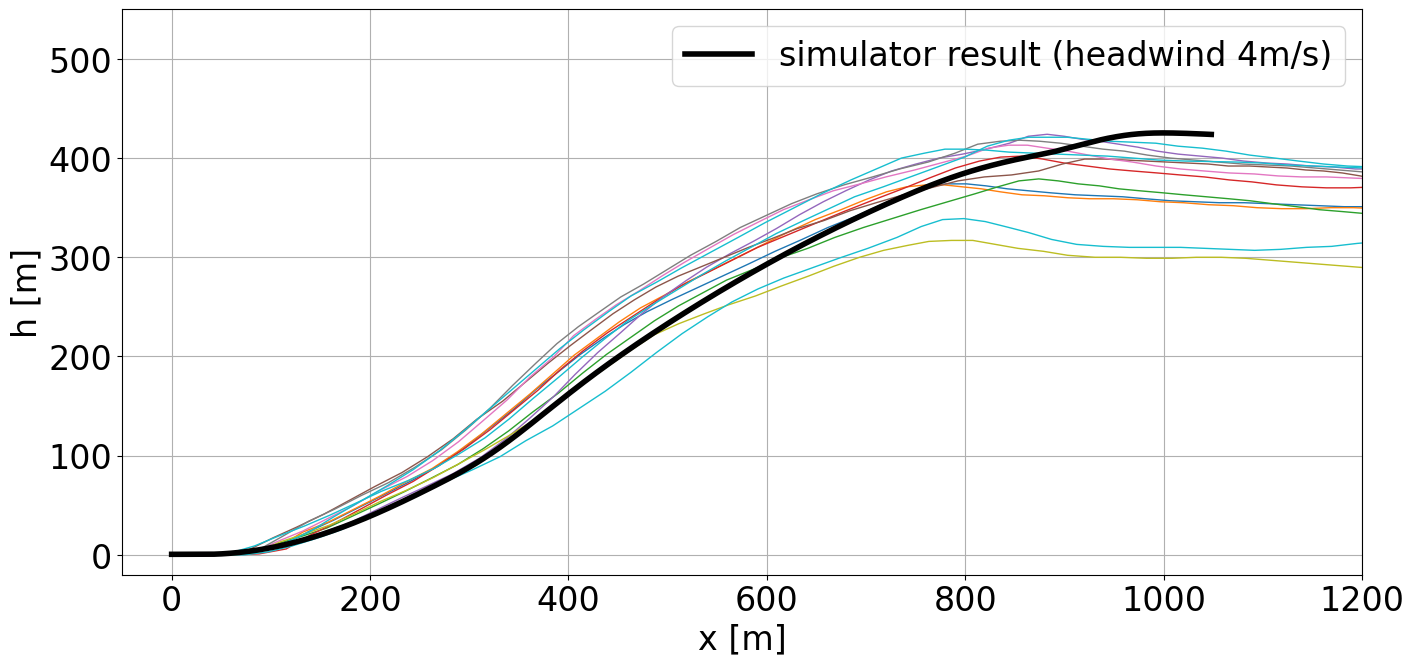

In [31]:
import importlib
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
from matplotlib.animation import FFMpegWriter, FuncAnimation, PillowWriter, writers
from matplotlib.collections import LineCollection

plt.rcParams["font.size"] = 24

fig, ax = plt.subplots(1, 1, figsize=(16, 9))
for i, (file, df) in enumerate(df_dict.items()):
  if "ground_track_distance_m" in df.columns:
    color = cm.tab10( i % len(df_dict))
    ax.plot(df["ground_track_distance_m"], df["relative_altitude_m"], linewidth=1, color=color)
  elif "x_m" in df.columns:
    ax.plot(df["x_m"], df["relative_altitude_m"], label="simulator result (headwind 4m/s)", color="k", linewidth=4)

ax.set_xlabel("x [m]")
ax.set_ylabel("h [m]")
ax.grid(True)
ax.set_xlim(-50, 1200)
ax.set_ylim(-20, 550)
ax.set_aspect("equal")

ax.legend(loc="best")
# fig.tight_layout()
fig.savefig(processed_directory / "winch_launch_igc_vs_simulator.png")

## 7. 自分のデータに合わせて変更するとき

通常、同じ形式の IGC を変換するだけなら `igc_to_df()` を書き換える必要はない。変更したい内容と主な修正箇所は次のとおりである。

| やりたいこと | 主な変更箇所 |
|---|---|
| 別の IGC を解析する | `data/flight_validation/raw/` へ `.igc` を置く。通常コード変更不要 |
| 1ファイルだけ解析する | `files = sorted(glob.glob("*.igc"))` を使わず `igc_to_df("...")` を直接呼ぶ |
| CSV を保存しない | `to_csv(...)` を実行しない |
| CSV に pandas index を保存しない | `to_csv(..., index=False)` |
| 滑走開始の探索範囲を変更する | `takeoff_search_window_s` |
| 静止判定速度を変更する | `stationary_ground_speed_kmh` |
| 出力列を変更する | `igc_to_df()` 最後の `return df_B[[...]]` |
| NED 座標変換そのものを変更する | `_geodetic_to_ned()` |
| シミュレータ CSV を変更する | `simulator_file` |
| シミュレータ比較をしない | `simulator_file` の読み込みを削除 / コメントアウト |
| 図の水平表示範囲を変更する | `ax.set_xlim(...)` |

### 離陸滑走開始検出を変更するとき

`takeoff_search_window_s` と `stationary_ground_speed_kmh` は、単なる表示設定ではなく **データの原点を決める条件**である。変更すると、

- `time_s`
- `x_m`, `y_m`, `z_m`
- `relative_altitude_m`
- `ground_track_distance_m`

の原点がすべて変わる。

変更後は、滑走開始付近の IGC / CSV を確認し、

1. `time_s = 0` が最後の静止サンプルになっているか
2. 次の数秒で継続的な前進が始まっているか
3. `takingOff` より十分前すぎる点を選んでいないか

を確認する。

### `LXNA::PHASE:takingOff` が存在しない IGC

現在の `igc_to_df()` は `LXNA::PHASE:takingOff` を探索アンカーとして必要とするため、この L-record を記録しない logger の IGC にはそのままでは使用できない。その場合は離陸滑走開始検出ロジックを別の基準へ変更する必要がある。

### NED と相対高度の符号

NED は Down 正なので、上昇時には通常 `z_m < 0` となる。一方、`relative_altitude_m` は高度増加を正としているため、局所的には概ね

$$
\mathrm{relative\_altitude\_m}\approx -z_m
$$

となる。ただし `z_m` は WGS84/ECEF/NED の幾何学的変換結果であり、`relative_altitude_m` は GNSS altitude の単純差なので、厳密に同一の量ではない。
